# VQC шаг за шагом: от данных до обучения
### Один проход — вручную и в коде одновременно
**Данные:** Из 150 образцов Iris берем: образец №0 = setosa, образец №50 = versicolor  
**Архитектура:** 2 кубита, angle encoding, RY-ансатц  
**Цель:** понять КАЖДЫЙ шаг, числа в коде = числа на бумаге


## Импорты

In [2]:
import pennylane as qml
from pennylane import numpy as np
import numpy as _np
from sklearn.datasets import load_iris
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt

print(f"PennyLane: {qml.__version__}")


PennyLane: 0.42.3


## Шаг 1 — Берём конкретные образцы из Iris

Берём ровно 2 образца:
- **Образец №0** — setosa,     метка y = **-1**
- **Образец №50** — versicolor, метка y = **+1**

Признаки: столбец 0 (sepal length, длина чашелистика) и столбец 2 (petal length, длина лепестка).  
Итого **2 признака → 2 кубита**.


In [3]:
iris = load_iris()
IDX = [0, 50] # айди выбранных нами данных 
print('выбранные нами данные')
X_raw = iris.data[IDX]
y = iris.target[IDX]
print(X_raw, y, sep='\n')

выбранные нами данные
[[5.1 3.5 1.4 0.2]
 [7.  3.2 4.7 1.4]]
[0 1]


In [4]:
print('оставляем только признаки 0 и 2, для наших двух кубитов')
X_raw = X_raw[:, [0,2]]
print(X_raw)

оставляем только признаки 0 и 2, для наших двух кубитов
[[5.1 1.4]
 [7.  4.7]]


In [5]:
print('дальше меняем таргеты на -1 и 1 вместо 0 и 1')
y = _np.array([-1, 1])
print(y)

дальше меняем таргеты на -1 и 1 вместо 0 и 1
[-1  1]


In [6]:
print("─── Сырые данные ───────────────────────────────────────────")
print(f"  Образец  0 (setosa)     : sepal={X_raw[0,0]} см,  petal={X_raw[0,1]} см  →  y = {y[0]}")
print(f"  Образец 50 (versicolor) : sepal={X_raw[1,0]} см,  petal={X_raw[1,1]} см  →  y = {y[1]}")
print()
print("Это те числа, которые мы нормализуем в углы.")

─── Сырые данные ───────────────────────────────────────────
  Образец  0 (setosa)     : sepal=5.1 см,  petal=1.4 см  →  y = -1
  Образец 50 (versicolor) : sepal=7.0 см,  petal=4.7 см  →  y = 1

Это те числа, которые мы нормализуем в углы.


## Шаг 2 — Три типа кодирования (теория)

Прежде чем обработать данные квантовой схемой, их надо **закодировать в квантовые состояния**.  
Есть три основных метода:

---

### Базисное кодирование (Basis encoding)
- Каждый **бит** данных → состояние кубита: `0 → |0⟩`, `1 → |1⟩`
- Работает только с **бинарными** данными
- Пример: `x = [1, 0, 1]` → `|101⟩`
- **Когда:** задачи над битовыми строками, комбинаторная оптимизация

---

### Амплитудное кодирование (Amplitude encoding)
- Вектор данных `x = [x₁, x₂, ..., x_N]` (нормированный) → **амплитуды** квантового состояния
- `|ψ⟩ = x₁|00⟩ + x₂|01⟩ + x₃|10⟩ + x₄|11⟩` и т.д.
- **Преимущество:** `N` признаков → `log₂(N)` кубитов (экспоненциально компактно!)
- **Недостаток:** сложная и дорогая подготовка состояния
- Именно его использует Angelino et al. в нашей статье
- **Когда:** много признаков, когда важна экономия кубитов

---

### Угловое кодирование (Angle encoding) ← **мы используем это**
- Каждый **признак** → угол поворота кубита через гейт `RY`
- `1 признак = 1 кубит`
- `x = [x₀, x₁]` → `RY(x₀)` на кубит 0, `RY(x₁)` на кубит 1
- Просто, работает на реальном железе, легко понять
- **Когда:** небольшое число признаков, обучение классификатору

---

**Итого:** у нас 2 признака → 2 кубита → angle encoding с `RY`.  
Нормализуем признаки в диапазон `[0, π]` — это стандартный диапазон для `RY`.


### Причина почему мы делаем нормализацию: <br><br>>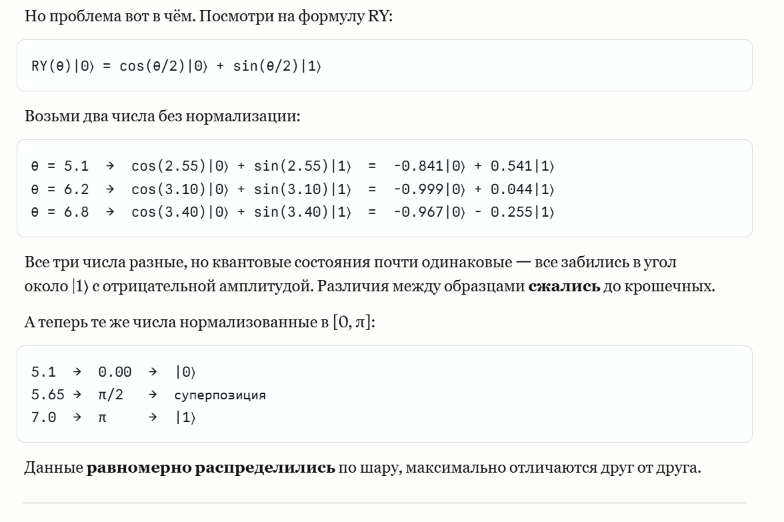

In [7]:
# Нормализация в [0, π] для angle encoding
scaler = MinMaxScaler(feature_range=(0, _np.pi))
X = scaler.fit_transform(X_raw)

print("─── После нормализации (углы в радианах) ───────────────────")
print(f"  Setosa     x = [{X[0,0]:.4f}, {X[0,1]:.4f}]  рад")
print(f"  Versicolor x = [{X[1,0]:.4f}, {X[1,1]:.4f}]  рад")
print()
print("  → setosa     = [0.000, 0.000]")
print("  → versicolor = [π,     π    ] ≈ [3.1416, 3.1416]")


─── После нормализации (углы в радианах) ───────────────────
  Setosa     x = [0.0000, 0.0000]  рад
  Versicolor x = [3.1416, 3.1416]  рад

  → setosa     = [0.000, 0.000]
  → versicolor = [π,     π    ] ≈ [3.1416, 3.1416]


## Что делает RY(θ) с кубитом?

Гейт `RY(θ)` вращает кубит вокруг оси Y сферы Блоха на угол θ:

$$RY(\theta)|0\rangle = \cos\!\frac{\theta}{2}|0\rangle + \sin\!\frac{\theta}{2}|1\rangle$$

$$RY(\theta)|1\rangle = -\sin\!\frac{\theta}{2}|0\rangle + \cos\!\frac{\theta}{2}|1\rangle$$

**Проверяем на наших данных:**

| Угол θ | RY(θ)|0⟩ | Смысл |
|--------|---------|-------|
| 0 | 1·|0⟩ + 0·|1⟩ = **|0⟩** | кубит остаётся в |0⟩ |
| π/2 ≈ 1.57 | 0.707·|0⟩ + 0.707·|1⟩ | равная суперпозиция |
| π ≈ 3.14 | 0·|0⟩ + 1·|1⟩ = **|1⟩** | кубит полностью перешёл в |1⟩ |

Значит:
- **Setosa** (x=[0,0]): оба кубита остаются в **|00⟩**
- **Versicolor** (x=[π,π]): оба кубита переходят в **|11⟩**

Это чистые, красивые состояния — идеально для проверки вручную.


In [8]:
for theta, name in [(0, "θ=0"), (_np.pi/2, "θ=π/2"), (_np.pi, "θ=π")]:
    a0 = _np.cos(theta/2)
    a1 = _np.sin(theta/2)
    print(f"  RY({name})|0⟩ = {a0:+.4f}|0⟩ + {a1:+.4f}|1⟩")

  RY(θ=0)|0⟩ = +1.0000|0⟩ + +0.0000|1⟩
  RY(θ=π/2)|0⟩ = +0.7071|0⟩ + +0.7071|1⟩
  RY(θ=π)|0⟩ = +0.0000|0⟩ + +1.0000|1⟩


## Шаг 3 — Архитектура схемы

```
  кубит 0: ──[RY(x₀)]──[RY(θ₀)]──●──────[Z измерение]
                                 │
  кубит 1: ──[RY(x₁)]──[RY(θ₁)]──⊕──────
```

**Три части:**
1. `RY(x₀), RY(x₁)` — **angle encoding**: кодируем данные
2. `RY(θ₀), RY(θ₁)` — **ансатц**: обучаемые параметры (θ мы обновляем)
3. `CNOT` — запутывание: кубит 0 управляет кубитом 1
4. `⟨Z₀⟩` — измеряем математическое ожидание PauliZ на кубите 0

**Что возвращает ⟨Z₀⟩:**
- Если кубит 0 скорее в |0⟩ → ⟨Z₀⟩ близко к **+1**
- Если кубит 0 скорее в |1⟩ → ⟨Z₀⟩ близко к **-1**
- Значение всегда в диапазоне [-1, +1]

Параметры θ = [θ₀, θ₁] — это то что мы обучаем. Начинаем с θ = [0.5, 0.5].


Начальные параметры: θ = [0.5 0.5]

Схема для setosa:


(<Figure size 600x300 with 1 Axes>, <Axes: >)

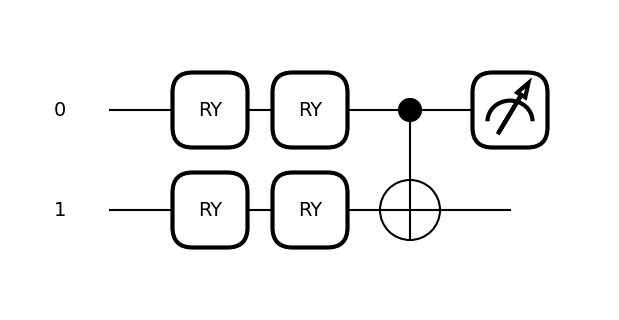

In [9]:
dev = qml.device("default.qubit", wires=2)

@qml.qnode(dev)
def circuit(params, x):
    # ── Angle encoding ──
    qml.RY(x[0], wires=0)
    qml.RY(x[1], wires=1)
    # ── Ансатц ──────────
    qml.RY(params[0], wires=0)
    qml.RY(params[1], wires=1)
    qml.CNOT(wires=[0, 1])
    # ── Измерение ───────
    return qml.expval(qml.PauliZ(0))

# Начальные параметры
params = np.array([0.5, 0.5], requires_grad=True)
print(f"Начальные параметры: θ = {params}")
print()
print("Схема для setosa:")
qml.draw_mpl(circuit)(params, X[0])


## Шаг 4 — Один прямой проход (вручную для setosa)

**Вход:** setosa, x = [0.0, 0.0], θ = [0.5, 0.5]

---

**Начальное состояние:** |00⟩

**После encoding RY(0) на оба кубита:**  
RY(0)|0⟩ = |0⟩ — ничего не меняется.  
Состояние: **|00⟩ = 1·|00⟩ + 0·|01⟩ + 0·|10⟩ + 0·|11⟩**

---

**После ансатца RY(0.5) на кубит 0 и кубит 1:**

RY(0.5)|0⟩ = cos(0.25)|0⟩ + sin(0.25)|1⟩ ≈ **0.9689|0⟩ + 0.2474|1⟩**

Два кубита — тензорное произведение:  
|ψ⟩ = (0.9689|0⟩ + 0.2474|1⟩) ⊗ (0.9689|0⟩ + 0.2474|1⟩)

|ψ⟩ = 0.9388·|00⟩ + 0.2397·|01⟩ + 0.2397·|10⟩ + 0.0612·|11⟩

---

**После CNOT (управляющий=кубит0, цель=кубит1):**  
Правило: если кубит0 = |1⟩, то кубит1 меняется на противоположный.

- |00⟩ → |00⟩ (кубит0=0, не меняем)
- |01⟩ → |01⟩ (кубит0=0, не меняем)  
- |10⟩ → |11⟩ (кубит0=1, **меняем**!)
- |11⟩ → |10⟩ (кубит0=1, **меняем**!)

|ψ'⟩ = 0.9388·|00⟩ + 0.2397·|01⟩ + **0.0612·|10⟩** + **0.2397·|11⟩**

---

**Измерение ⟨Z₀⟩:**  
P(кубит0=|0⟩) = |0.9388|² + |0.2397|² = 0.8814 + 0.0575 = **0.9389**  
P(кубит0=|1⟩) = |0.0612|² + |0.2397|² = 0.0037 + 0.0575 = **0.0612**

⟨Z₀⟩ = 0.9389 − 0.0612 = **0.8777**

Вывод схемы ≈ **+0.878** для setosa с меткой **-1**. Пока схема сильно ошибается!


In [10]:
# Запускаем код — должны получить ~0.8777
x_setosa     = np.array(X[0])
x_versicolor = np.array(X[1])

out_setosa     = float(circuit(params, x_setosa))
out_versicolor = float(circuit(params, x_versicolor))

print("─── Прямой проход ──────────────────────────────────────────")
print(f"  Setosa     (y=-1): ŷ = {out_setosa:+.4f}   (ожидали ~+0.8777)")
print(f"  Versicolor (y=+1): ŷ = {out_versicolor:+.4f}   (ожидали ~-0.8777)")
print()
print("Оба ответа — неправильные! Схема ещё не обучена.")
print(f"  Setosa должен быть -1, а выдаёт {out_setosa:+.3f}")
print(f"  Versicolor должен быть +1, а выдаёт {out_versicolor:+.3f}")


─── Прямой проход ──────────────────────────────────────────
  Setosa     (y=-1): ŷ = +0.8776   (ожидали ~+0.8777)
  Versicolor (y=+1): ŷ = -0.8776   (ожидали ~-0.8777)

Оба ответа — неправильные! Схема ещё не обучена.
  Setosa должен быть -1, а выдаёт +0.878
  Versicolor должен быть +1, а выдаёт -0.878


## Шаг 5 — Функция потерь (Loss)

Используем **MSE (Mean Squared Error)**:

$$L = \frac{1}{N}\sum_{i=1}^{N}(\hat{y}_i - y_i)^2$$

**Вручную:**

L_setosa = (0.8777 − (−1))² = (1.8777)² = **3.526**

L_versicolor = (−0.8777 − (+1))² = (−1.8777)² = **3.526**

L_total = (3.526 + 3.526) / 2 = **3.526**

Большой loss — потому что оба ответа почти противоположны правильным.


In [11]:
def mse_loss(params, X_data, y_data):
    preds = np.array([circuit(params, np.array(x)) for x in X_data])
    return np.mean((preds - y_data) ** 2)

loss = float(mse_loss(params, X, y))

print("─── Функция потерь MSE ─────────────────────────────────────")
print(f"  L_setosa     = ({out_setosa:.4f} - ({y[0]:.0f}))² = {(out_setosa-y[0])**2:.4f}")
print(f"  L_versicolor = ({out_versicolor:.4f} - ({y[1]:.0f}))² = {(out_versicolor-y[1])**2:.4f}")
print(f"  L_total      = {loss:.4f}")


─── Функция потерь MSE ─────────────────────────────────────
  L_setosa     = (0.8776 - (-1))² = 3.5253
  L_versicolor = (-0.8776 - (1))² = 3.5253
  L_total      = 3.5253


## Шаг 6 — Правило сдвига параметров (Parameter Shift Rule)

Нам нужен градиент ∂L/∂θ — но как его вычислить для квантовой схемы?

В классических нейросетях используют **backpropagation**.  
В квантовых схемах это не работает — измерение разрушает квантовое состояние.

**Решение: Parameter Shift Rule (Mitarai et al., 2018)**

Для любого параметра θᵢ в гейте вида `RY(θ)`:

$$\frac{\partial \hat{y}}{\partial \theta_i} = \frac{1}{2}\left[\text{circuit}\left(\theta_i + \frac{\pi}{2}\right) - \text{circuit}\left(\theta_i - \frac{\pi}{2}\right)\right]$$

Это **точная** формула (не приближение!), потому что RY — это тригонометрическая функция.

**Откуда берётся π/2:**  
RY(θ) = exp(−iθY/2), собственные значения Y равны ±1.  
Для таких гейтов производная точно выражается через сдвиг на π/2.

---

**Цепное правило для loss:**

$$\frac{\partial L}{\partial \theta_i} = 2(\hat{y} - y) \cdot \frac{\partial \hat{y}}{\partial \theta_i}$$

---

**Вручную для θ₀ на примере setosa (x=[0,0]):**

Текущий θ₀ = 0.5, нам нужны:
- circuit(θ₀ = 0.5 + π/2 ≈ **2.0708**, θ₁=0.5, x_setosa)  
- circuit(θ₀ = 0.5 − π/2 ≈ **−1.0708**, θ₁=0.5, x_setosa)

Посчитаем в следующей ячейке и сравним с кодом.


In [12]:
print("─── Parameter Shift Rule: ручной расчёт ────────────────────")
print()

theta0, theta1 = 0.5, 0.5
shift = _np.pi / 2

# ── Для setosa, параметр θ₀ ──
params_plus  = np.array([theta0 + shift, theta1])
params_minus = np.array([theta0 - shift, theta1])

c_plus  = float(circuit(params_plus,  np.array(X[0])))
c_minus = float(circuit(params_minus, np.array(X[0])))

grad_circuit_theta0_setosa = (c_plus - c_minus) / 2
grad_loss_theta0_setosa = 2 * (out_setosa - y[0]) * grad_circuit_theta0_setosa

print(f"  Setosa, ∂ŷ/∂θ₀:")
print(f"    circuit(θ₀ + π/2) = circuit({theta0+shift:.4f}) = {c_plus:+.4f}")
print(f"    circuit(θ₀ - π/2) = circuit({theta0-shift:.4f}) = {c_minus:+.4f}")
print(f"    ∂ŷ/∂θ₀ = ({c_plus:.4f} - {c_minus:.4f}) / 2 = {grad_circuit_theta0_setosa:+.4f}")
print(f"    ∂L/∂θ₀ = 2×({out_setosa:.4f}-({y[0]:.0f}))×{grad_circuit_theta0_setosa:.4f} = {grad_loss_theta0_setosa:+.4f}")
print()

# ── Для versicolor, параметр θ₀ ──
c_plus_v  = float(circuit(params_plus,  np.array(X[1])))
c_minus_v = float(circuit(params_minus, np.array(X[1])))

grad_circuit_theta0_verc = (c_plus_v - c_minus_v) / 2
grad_loss_theta0_verc = 2 * (out_versicolor - y[1]) * grad_circuit_theta0_verc

print(f"  Versicolor, ∂ŷ/∂θ₀:")
print(f"    circuit(θ₀ + π/2) = {c_plus_v:+.4f}")
print(f"    circuit(θ₀ - π/2) = {c_minus_v:+.4f}")
print(f"    ∂ŷ/∂θ₀ = {grad_circuit_theta0_verc:+.4f}")
print(f"    ∂L/∂θ₀ = {grad_loss_theta0_verc:+.4f}")
print()

total_grad_theta0 = (grad_loss_theta0_setosa + grad_loss_theta0_verc) / 2
print(f"  Итоговый ∂L_total/∂θ₀ = ({grad_loss_theta0_setosa:.4f} + {grad_loss_theta0_verc:.4f}) / 2 = {total_grad_theta0:+.4f}")


─── Parameter Shift Rule: ручной расчёт ────────────────────

  Setosa, ∂ŷ/∂θ₀:
    circuit(θ₀ + π/2) = circuit(2.0708) = -0.4794
    circuit(θ₀ - π/2) = circuit(-1.0708) = +0.4794
    ∂ŷ/∂θ₀ = (-0.4794 - 0.4794) / 2 = -0.4794
    ∂L/∂θ₀ = 2×(0.8776-(-1))×-0.4794 = -1.8003

  Versicolor, ∂ŷ/∂θ₀:
    circuit(θ₀ + π/2) = +0.4794
    circuit(θ₀ - π/2) = -0.4794
    ∂ŷ/∂θ₀ = +0.4794
    ∂L/∂θ₀ = -1.8003

  Итоговый ∂L_total/∂θ₀ = (-1.8003 + -1.8003) / 2 = -1.8003


### Проверяем — PennyLane должен дать тот же градиент
`qml.grad` автоматически применяет parameter shift rule внутри.

In [13]:
grad_fn = qml.grad(mse_loss)
gradients = grad_fn(params, X, y)

print("─── Сравнение: ручной расчёт vs qml.grad ───────────────────")
print(f"  ∂L/∂θ₀: наш расчёт = {total_grad_theta0:+.4f}   qml.grad = {float(gradients[0]):+.4f}")
print()
print("Числа должны совпадать!")


─── Сравнение: ручной расчёт vs qml.grad ───────────────────
  ∂L/∂θ₀: наш расчёт = -1.8003   qml.grad = -1.8003

Числа должны совпадать!


## Шаг 7 — Один шаг градиентного спуска

Обновление параметров:

$$\theta_i \leftarrow \theta_i - \alpha \cdot \frac{\partial L}{\partial \theta_i}$$

где α = learning rate = 0.1

**Вручную:**

θ₀_new = 0.5 − 0.1 × (∂L/∂θ₀)

Если ∂L/∂θ₀ отрицательный → θ₀ увеличится → схема сдвинется в нужную сторону.

**Почему это правильно:**  
- Для setosa нам нужен ⟨Z₀⟩ → −1 (больше вероятность |1⟩)  
- Больший θ₀ делает больше амплитуды в |1⟩  
- Отрицательный градиент → θ₀ растёт ✓


In [14]:
lr = 0.1
grads = grad_fn(params, X, y)

params_new = params - lr * grads

print("─── Один шаг градиентного спуска ──────────────────────────")
print(f"  Старые параметры: θ = [{float(params[0]):.4f}, {float(params[1]):.4f}]")
print(f"  Градиенты:     ∂L = [{float(grads[0]):.4f}, {float(grads[1]):.4f}]")
print(f"  Новые параметры: θ = [{float(params_new[0]):.4f}, {float(params_new[1]):.4f}]")
print()

out_s_new = float(circuit(params_new, np.array(X[0])))
out_v_new = float(circuit(params_new, np.array(X[1])))
loss_new = float(mse_loss(params_new, X, y))

print("─── Проверяем: стало ли лучше? ─────────────────────────────")
print(f"  Setosa     (y=-1): было {out_setosa:+.4f}  →  стало {out_s_new:+.4f}  (ближе к -1?)")
print(f"  Versicolor (y=+1): было {out_versicolor:+.4f}  →  стало {out_v_new:+.4f}  (ближе к +1?)")
print(f"  Loss: было {float(mse_loss(params, X, y)):.4f}  →  стало {loss_new:.4f}  (меньше?)")


─── Один шаг градиентного спуска ──────────────────────────
  Старые параметры: θ = [0.5000, 0.5000]
  Градиенты:     ∂L = [-1.8003, 0.0000]
  Новые параметры: θ = [0.6800, 0.5000]

─── Проверяем: стало ли лучше? ─────────────────────────────
  Setosa     (y=-1): было +0.8776  →  стало +0.7776  (ближе к -1?)
  Versicolor (y=+1): было -0.8776  →  стало -0.7776  (ближе к +1?)
  Loss: было 3.5253  →  стало 3.1597  (меньше?)


## Шаг 8 — Полный цикл обучения

Теперь повторяем шаги 4–7 много раз.  
Каждая итерация:  
1. Прямой проход → ŷ  
2. Вычисляем loss  
3. Parameter shift rule → градиенты  
4. Обновляем θ  
5. Повторяем  

Используем **Adam** — умный вариант градиентного спуска с адаптивным learning rate.


In [15]:
from pennylane.optimize import AdamOptimizer

# Заново с начальных параметров
params = np.array([0.5, 0.5], requires_grad=True)
opt = AdamOptimizer(stepsize=0.3)

losses = []
outputs_s = []
outputs_v = []
N_EPOCHS = 60

print(f"{'Эпоха':>6}  {'Loss':>8}  {'ŷ_setosa':>10}  {'ŷ_verc':>10}  {'Правильно?':>12}")
print("─" * 60)

for ep in range(N_EPOCHS):
    params, loss = opt.step_and_cost(
        lambda p: mse_loss(p, X, y), params
    )
    loss = float(loss)
    losses.append(loss)

    ys = float(circuit(params, np.array(X[0])))
    yv = float(circuit(params, np.array(X[1])))
    outputs_s.append(ys)
    outputs_v.append(yv)

    correct_s = "✓" if ys < 0 else "✗"
    correct_v = "✓" if yv > 0 else "✗"

    if ep < 5 or ep % 10 == 9:
        print(f"{ep+1:>6}  {loss:>8.4f}  {ys:>+10.4f}{correct_s}  {yv:>+10.4f}{correct_v}")

print()
print(f"Финал: setosa={float(circuit(params,np.array(X[0]))):+.4f} (цель=-1),  versicolor={float(circuit(params,np.array(X[1]))):+.4f} (цель=+1)")
print(f"Точность: {'100%' if float(circuit(params,np.array(X[0])))<0 and float(circuit(params,np.array(X[1])))>0 else 'нет'}")


 Эпоха      Loss    ŷ_setosa      ŷ_verc    Правильно?
────────────────────────────────────────────────────────────
     1    3.5253     +0.6967✗     -0.6967✗
     2    2.8788     +0.4547✗     -0.4547✗
     3    2.1160     +0.1712✗     -0.1712✗
     4    1.3718     -0.1275✓     +0.1275✓
     5    0.7612     -0.4106✓     +0.4106✓
    10    0.0001     -0.9993✓     +0.9993✓
    20    0.1601     -0.6024✓     +0.6024✓
    30    0.0067     -0.9413✓     +0.9413✓
    40    0.0000     -0.9975✓     +0.9975✓
    50    0.0006     -0.9732✓     +0.9732✓
    60    0.0011     -0.9672✓     +0.9672✓

Финал: setosa=-0.9672 (цель=-1),  versicolor=+0.9672 (цель=+1)
Точность: 100%


## Визуализация обучения

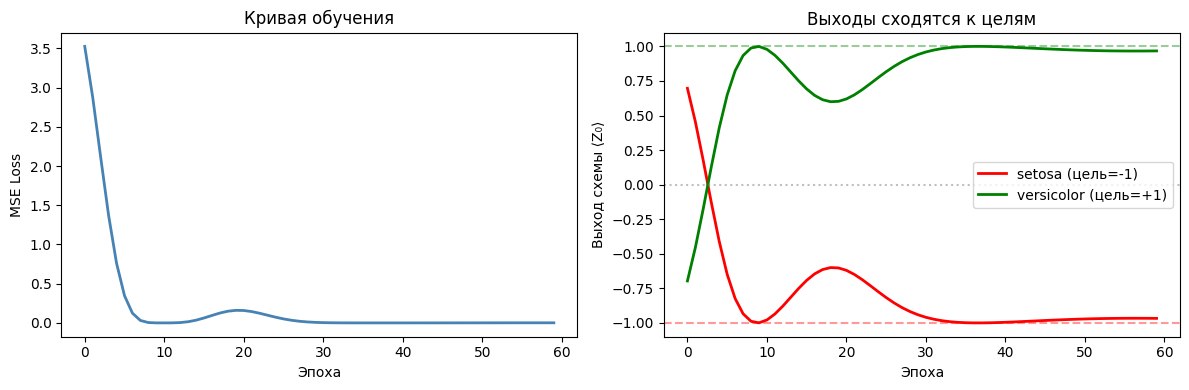

Сохранено: vqc_training.png


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(losses, 'steelblue', lw=2)
axes[0].set_xlabel("Эпоха"); axes[0].set_ylabel("MSE Loss")
axes[0].set_title("Кривая обучения")

axes[1].plot(outputs_s, 'r-', lw=2, label='setosa (цель=-1)')
axes[1].plot(outputs_v, 'g-', lw=2, label='versicolor (цель=+1)')
axes[1].axhline(-1, color='r', ls='--', alpha=0.4)
axes[1].axhline(+1, color='g', ls='--', alpha=0.4)
axes[1].axhline(0, color='gray', ls=':', alpha=0.5)
axes[1].set_xlabel("Эпоха"); axes[1].set_ylabel("Выход схемы ⟨Z₀⟩")
axes[1].set_title("Выходы сходятся к целям"); axes[1].legend()

plt.tight_layout()
plt.savefig("vqc_training.png", dpi=130, bbox_inches='tight')
plt.show()
print("Сохранено: vqc_training.png")


## Бонус: Как отличить Barren Plateau от других проблем?

Это важный вопрос — плохое обучение может иметь разные причины.

### Диагностика через дисперсию градиентов

**Главный инструмент:** измерить Var[∂C/∂θ] на *случайных* инициализациях *до* обучения.

| Проблема | Симптом | Диагностика |
|----------|---------|-------------|
| **Barren Plateau** | Gradient ≈ 0 с самого старта, и это повторяется для ЛЮБЫХ случайных θ | Var[grad] < 10⁻⁶ при n≥6 кубитах |
| **Локальный минимум** | Loss перестаёт убывать, но gradient ≠ 0 | Gradient не маленький, но loss застрял |
| **Маленький lr** | Обучение идёт, но очень медленно | Gradient нормальный, просто шаг мал |
| **Переобучение** | Train loss ↓, Test loss ↑ | Loss на тесте растёт |
| **Шум железа** | Нестабильные результаты | Дисперсия выходов при повторных измерениях |

### Практический тест на BP:


In [69]:
print("─── Диагностика Barren Plateau ─────────────────────────────")
print()

# Вычисляем дисперсию градиентов для нашей МАЛЕНЬКОЙ схемы (2 кубита)
n_samples_bp = 100
grad_samples = []

for _ in range(n_samples_bp):
    p_rand = np.array(_np.random.uniform(0, 2*_np.pi, 2), requires_grad=True)
    g = grad_fn(p_rand, X, y)
    grad_samples.append(float(g[0]))

var_grad = _np.var(grad_samples)

print(f"  2 кубита, 1 слой: Var[∂L/∂θ₀] = {var_grad:.4f}")
print()
print("  Если Var >> 10⁻⁶ → BP нет, обучать можно.")
print("  Если Var < 10⁻⁶  → вероятно BP (для 2 кубитов этого не будет,")
print("                      но при n=8+ кубитах и глубоких схемах — да)")
print()
print("  Вывод для нашей схемы:")
if var_grad > 1e-4:
    print(f"  ✓ Var = {var_grad:.4f} — градиенты информативны, BP нет!")
else:
    print(f"  ⚠ Var = {var_grad:.6f} — возможен BP, нужно смотреть внимательнее")


─── Диагностика Barren Plateau ─────────────────────────────

  2 кубита, 1 слой: Var[∂L/∂θ₀] = 2.6858

  Если Var >> 10⁻⁶ → BP нет, обучать можно.
  Если Var < 10⁻⁶  → вероятно BP (для 2 кубитов этого не будет,
                      но при n=8+ кубитах и глубоких схемах — да)

  Вывод для нашей схемы:
  ✓ Var = 2.6858 — градиенты информативны, BP нет!
